# Lab Assignment 8
## Neural Machine Translation for English-to-German using LSTMs
---

### Objective

The goal of this assignment is to build, train, and test a Neural Machine Translation (NMT) model
capable of translating English sentences into German. You will achieve this by adapting a
sequence-to-sequence (Seq2Seq) model based on Long Short-Term Memory (LSTM) networks.

### Provided Materials

A complete working notebook that implements an **English-to-French** translator has been shared with you. Your task is to modify the logic in that
reference code to work for the English-to-German language pair.

**You are expected to write the code yourself.** This notebook tells you *what* each task must
produce — the function names, the variables, and the exact output your code must print — but not
*how* to write it. Adapt the reference notebook.

### Marks

| Task | Description | Marks |
|---|---|---|
| **Task 1** | Data Adaptation | **4** |
| **Task 2** | Model Training | **5** |
| **Task 3** | Inference and Translation | **6** |
| **Task 4** | Beam Search Decoding | **5** |
| | **Total** | **20** |

---

### Before you start

- **Use a GPU.** In Colab: `Runtime → Change runtime type → T4 GPU`. Training 40 epochs takes
  roughly **15–25 minutes on a GPU** and well over an hour on CPU. **Start Task 2 training early**
  and write your Task 4 code while it runs.
- **The reference notebook is incomplete.** It calls a function `decode_sequence(...)` that it
  never defines. Writing that function is part of Task 3.
- Saving to `.h5` prints a "legacy format" warning on current Keras. It is harmless.
- Do **not** change the model architecture. Tasks 1–3 adapt the data and the inference code;
  Task 4 improves the *decoding*, not the model.

---
## Setup

These are the only values given to you. Everything else you write yourself.

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense

tf.keras.utils.set_random_seed(42)   # reproducible run

batch_size  = 64
epochs      = 40          # Task 2 requires at least 40
latent_dim  = 256
num_samples = 10000

print("TensorFlow", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices('GPU')))

TensorFlow 2.21.0
GPU available: False


---
# Task 1: Data Adaptation &nbsp;&nbsp;*(4 marks)*

Your first task is to replace the data pipeline to use the English-to-German dataset.

1. In the data acquisition section of your code, download the English-German data uploaded in classroom.
2. After downloading and unzipping, ensure you update the `data_path` variable to point to the
   correct text file: `deu.txt`.
3. Run the data loading and preprocessing steps. **For your submission, report the following
   statistics** that are printed to the console:
   * `Number of samples:`
   * `Number of unique input tokens:`
   * `Number of unique output tokens:`
   * `Max sequence length for inputs:`

### What your code must create

| Variable | Holds |
|---|---|
| `input_texts`, `target_texts` | the English and German sentences |
| `input_characters`, `target_characters` | the sorted character vocabularies |
| `num_encoder_tokens`, `num_decoder_tokens` | sizes of those vocabularies |
| `max_encoder_seq_length`, `max_decoder_seq_length` | longest input and output |
| `input_token_index`, `target_token_index` | character → index dictionaries |
| `encoder_input_data`, `decoder_input_data`, `decoder_target_data` | the three one-hot tensors |

### Output your code must print

```
Number of samples: ...
Number of unique input tokens: ...
Number of unique output tokens: ...
Max sequence length for inputs: ...
Max sequence length for outputs: ...
```

### Hints

- The German file has the **same three-column tab-separated format** as the French one, so the
  parsing logic does not change: splitting a line on tabs gives `[english, german, attribution]`.
- Wrap every German sentence with a **start marker** (`'\t'`) and an **end marker** (`'\n'`).
  Without them the decoder never learns where a translation begins or ends.
- **Teacher forcing.** `decoder_target_data` is `decoder_input_data` shifted **left by one step**:
  at position `t` the decoder must *predict* the character it was *given* at position `t`. There
  is nothing to predict before the start marker.
- Pad the unused positions of all three tensors with the space character.
- German adds characters English does not have (`ä ö ü ß`, and `Ä Ö Ü`), so expect
  `num_decoder_tokens` to be noticeably larger than `num_encoder_tokens`.

In [2]:
# ---------------- TASK 1 ----------------
import os, zipfile, urllib.request

# TODO 1: download and unzip the English-German archive, then set data_path
data_dir  = 'deu-eng'
data_path = os.path.join(data_dir, 'deu.txt')
if not os.path.exists(data_path):
    zip_path = 'deu-eng.zip'
    if not os.path.exists(zip_path):
        req = urllib.request.Request('https://www.manythings.org/anki/deu-eng.zip',
                                     headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req) as r, open(zip_path, 'wb') as f:
            f.write(r.read())
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(data_dir)
print('data_path =', data_path)

# TODO 2: read the file and build the sentence lists and character vocabularies
input_texts, target_texts = [], []
input_characters, target_characters = set(), set()

with open(data_path, 'r', encoding='utf-8') as f:
    lines = f.read().split('\n')

for line in lines[: min(num_samples, len(lines) - 1)]:
    input_text, target_text, _ = line.split('\t')
    target_text = '\t' + target_text + '\n'          # start marker + end marker
    input_texts.append(input_text)
    target_texts.append(target_text)
    input_characters.update(input_text)
    target_characters.update(target_text)

input_characters  = sorted(list(input_characters))
target_characters = sorted(list(target_characters))

# TODO 3: vocabulary sizes and maximum lengths
num_encoder_tokens = len(input_characters)
num_decoder_tokens = len(target_characters)
max_encoder_seq_length = max(len(t) for t in input_texts)
max_decoder_seq_length = max(len(t) for t in target_texts)

# TODO 4: character -> index dictionaries
input_token_index  = {ch: i for i, ch in enumerate(input_characters)}
target_token_index = {ch: i for i, ch in enumerate(target_characters)}

# TODO 5: print the five statistics
print('Number of samples:', len(input_texts))
print('Number of unique input tokens:', num_encoder_tokens)
print('Number of unique output tokens:', num_decoder_tokens)
print('Max sequence length for inputs:', max_encoder_seq_length)
print('Max sequence length for outputs:', max_decoder_seq_length)

# TODO 6: the three one-hot tensors (teacher forcing: target = input shifted left by one)
encoder_input_data  = np.zeros((len(input_texts), max_encoder_seq_length, num_encoder_tokens), dtype='float32')
decoder_input_data  = np.zeros((len(input_texts), max_decoder_seq_length, num_decoder_tokens), dtype='float32')
decoder_target_data = np.zeros((len(input_texts), max_decoder_seq_length, num_decoder_tokens), dtype='float32')

for i, (input_text, target_text) in enumerate(zip(input_texts, target_texts)):
    for t, char in enumerate(input_text):
        encoder_input_data[i, t, input_token_index[char]] = 1.
    encoder_input_data[i, t + 1:, input_token_index[' ']] = 1.
    for t, char in enumerate(target_text):
        decoder_input_data[i, t, target_token_index[char]] = 1.
        if t > 0:
            decoder_target_data[i, t - 1, target_token_index[char]] = 1.   # shift left by one
    decoder_input_data[i, t + 1:, target_token_index[' ']] = 1.
    decoder_target_data[i, t:, target_token_index[' ']] = 1.

print()
print('encoder_input_data ', encoder_input_data.shape)
print('decoder_input_data ', decoder_input_data.shape)
print('decoder_target_data', decoder_target_data.shape)
print('German-only characters:',
      ''.join(ch for ch in target_characters if ch not in input_characters and ch.isalpha()))

data_path = deu-eng/deu.txt
Number of samples: 10000
Number of unique input tokens: 70
Number of unique output tokens: 84
Max sequence length for inputs: 15
Max sequence length for outputs: 51



encoder_input_data  (10000, 15, 70)
decoder_input_data  (10000, 51, 84)
decoder_target_data (10000, 51, 84)
German-only characters: ZÄÖÜßäöü


### Task 1 — Results and explanation

| Statistic | Value |
|---|---|
| Number of samples | **10000** |
| Number of unique input tokens | **70** |
| Number of unique output tokens | **84** |
| Max sequence length for inputs | **15** |
| Max sequence length for outputs | **51** |

**What changed from the English→French reference:** only the data source. `data_path` now points to `deu-eng/deu.txt` (downloaded and unzipped from the English–German archive if not already present). The file has the same `english \t german \t attribution` format, so the parsing loop is unchanged.

**Explanation:**
- Each German sentence is wrapped as `'\t' + sentence + '\n'`. The tab is the **start marker** the decoder is given at step 0, and the newline is the **end marker** it must learn to produce so it knows when to stop.
- The output vocabulary (84) is larger than the input vocabulary (70) because German adds characters English does not have: **`Ä Ö Ü ä ö ü ß`** (and `Z`, which happens not to appear in the first 10k English sentences).
- The output max length (51) is much larger than the input (15) because German sentences are generally longer, and the two markers add 2 characters.
- **Teacher forcing:** `decoder_target_data[t]` = `decoder_input_data[t+1]`, i.e. the target is the input shifted **left by one step**. At each position the decoder is given the correct previous character and must predict the next one.
- Unused positions in all three one-hot tensors are padded with the space character.

---
# Task 2: Model Training &nbsp;&nbsp;*(5 marks)*

Next, you will train the LSTM-based Encoder-Decoder model on the new English-German dataset.

1. Modify the code to save your newly trained model with a distinct name (e.g.,
   `s2s_eng_ger.h5`) to differentiate it from the original French model.
2. Train the model on the English-German data for at least **40 epochs**. It is highly
   recommended to use a GPU accelerator in Google Colab for this step.
3. For your submission, provide a **screenshot** of the console output from the final epoch of
   training. The screenshot must clearly show the final values for `loss`, `accuracy`,
   `val_loss`, and `val_accuracy`.

### What your code must create

| Name | Is |
|---|---|
| `encoder_inputs`, `encoder_states` | the encoder input, and its two final states |
| `decoder_inputs` | the decoder input |
| `decoder_lstm`, `decoder_dense` | the decoder **layer objects** — Task 3 reuses these |
| `model` | the full training model, compiled |
| `history` | the return value of `model.fit(...)` |

### Output your code must print

- `model.summary()`
- the final epoch line showing `loss`, `accuracy`, `val_loss`, `val_accuracy`
- confirmation that the model was saved

### Hints

- The encoder keeps only its **final states** — this is the "thought vector". Its outputs are
  discarded.
- The decoder is connected to the encoder by exactly **one argument**. Find it in the reference
  code; without it you have two unrelated LSTMs.
- The decoder LSTM must return a prediction at *every* time step, not just the last one.
- Keep `decoder_lstm` and `decoder_dense` as named variables. In Task 3 you must reuse **these
  same trained layer objects** — building new ones gives you untrained weights.
- Train with `validation_split=0.2` so you have the `val_loss` and `val_accuracy` the task asks for.

In [3]:
# ---------------- TASK 2 ----------------

# TODO 7: encoder -- keep only its two final states (the "thought vector")
encoder_inputs = Input(shape=(None, num_encoder_tokens))
encoder = LSTM(latent_dim, return_state=True)
encoder_outputs, state_h, state_c = encoder(encoder_inputs)
encoder_states = [state_h, state_c]

# TODO 8: decoder, initialised from the encoder states
decoder_inputs = Input(shape=(None, num_decoder_tokens))
decoder_lstm = LSTM(latent_dim, return_sequences=True, return_state=True)
decoder_outputs, _, _ = decoder_lstm(decoder_inputs, initial_state=encoder_states)
decoder_dense = Dense(num_decoder_tokens, activation='softmax')
decoder_outputs = decoder_dense(decoder_outputs)

# TODO 9: build, compile, summarise
model = Model([encoder_inputs, decoder_inputs], decoder_outputs)
model.compile(optimizer='rmsprop', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

# TODO 10: train
history = model.fit([encoder_input_data, decoder_input_data], decoder_target_data,
                    batch_size=batch_size,
                    epochs=epochs,
                    validation_split=0.2,
                    verbose=2)

# TODO 11: save under a German-specific name
model.save('s2s_eng_ger.h5')
print("\nModel saved as 's2s_eng_ger.h5'")

# TODO 12: final epoch metrics
h = history.history
print(f"\nFinal epoch ({len(h['loss'])}/{epochs}): "
      f"loss: {h['loss'][-1]:.4f} - accuracy: {h['accuracy'][-1]:.4f} - "
      f"val_loss: {h['val_loss'][-1]:.4f} - val_accuracy: {h['val_accuracy'][-1]:.4f}")

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, None, 70)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, None, 84)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ [(None, 256),     │    334,848 │ input_layer[0][0] │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ [(None, None,     │    349,184 │ input_layer_1[0]… │
│                     │ 256), (None,      │            │ lstm[0][1],       │
│                     │ 256), (None,      │            │ lstm[0][2]        │
│                     │ 256)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, None, 84)  │     21,588 │ lstm_1[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 705,620 (2.69 MB)

 Trainable params: 705,620 (2.69 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40


... (76 outputs left out)

125/125 - 7s - 55ms/step - accuracy: 0.9006 - loss: 0.3416 - val_accuracy: 0.8570 - val_loss: 0.5063


Epoch 40/40


125/125 - 7s - 54ms/step - accuracy: 0.9019 - loss: 0.3365 - val_accuracy: 0.8583 - val_loss: 0.5063



Model saved as 's2s_eng_ger.h5'

Final epoch (40/40): loss: 0.3365 - accuracy: 0.9019 - val_loss: 0.5063 - val_accuracy: 0.8583


### Task 2 — Results and explanation

**Final epoch (40/40):**

| loss | accuracy | val_loss | val_accuracy |
|---|---|---|---|
| **0.3365** | **0.9019** | **0.5063** | **0.8583** |

**Screenshot of the final epoch of training** (from the Task 2 output above, showing `loss`, `accuracy`, `val_loss`, `val_accuracy`):

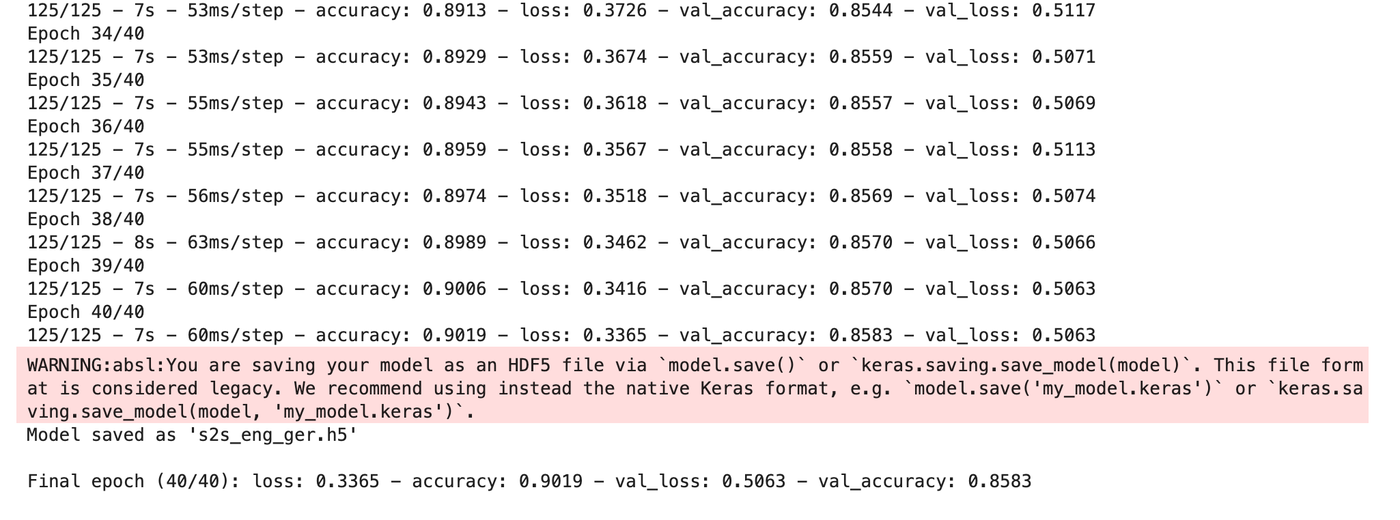

The trained model is saved as **`s2s_eng_ger.h5`** (a German-specific name, separate from the French model).

**Architecture (unchanged from the reference, `latent_dim = 256`, 705,620 parameters):**
- **Encoder:** an LSTM with `return_state=True`. Its outputs are discarded and only the final states `[h, c]` are kept. This is the "thought vector" that summarises the English sentence.
- **Decoder:** an LSTM with `return_sequences=True` (a prediction at every time step) and `return_state=True` (needed later for inference). It is connected to the encoder through **`initial_state=encoder_states`**. Without that argument the two LSTMs would be unrelated.
- **Output:** a `Dense(num_decoder_tokens, softmax)` layer gives a probability distribution over the 84 German characters at each step.
- Trained with `rmsprop` and `categorical_crossentropy`, `batch_size=64`, `validation_split=0.2` (8000 train / 2000 validation).

**Observations:** training loss fell steadily from 1.40 to 0.34. Validation loss fell from 1.30 to about 0.51 and flattened after roughly epoch 30 (0.514 → 0.506), while training loss kept falling. The growing gap (0.34 vs 0.51) shows the model is starting to overfit. The accuracy is **per character** under teacher forcing, so 86% validation accuracy does **not** mean 86% of sentences are translated correctly. At inference the model has to consume its own predictions, and one wrong character affects everything after it.

---
# Task 3: Inference and Translation &nbsp;&nbsp;*(6 marks)*

After the model is trained, you will test its ability to translate new English sentences into
German.

1. Ensure the inference part of your code is **correctly set up** to use the new German model and
   its corresponding vocabulary.
2. Using your translation function, translate the following five English sentences:
   * `I am very tired.`
   * `You are right.`
   * `He is a doctor.`
   * `Can you help me?`
   * `Let's go home.`
3. Present the translation results clearly in your submission, showing the original English input
   and the model's German translation for each of the five sentences.

### Why inference needs two new models

During training the decoder was always handed the *correct* previous character (teacher forcing).
At inference there is no correct answer, so the decoder must consume **its own predictions**, one
character at a time. The training model cannot do this, so you re-wire the **already-trained
layers** into two new models. No new training happens.

### What your code must create

| Name | Does |
|---|---|
| `encoder_model` | English sentence → the two encoder states. Run **once** per sentence |
| `decoder_model` | (one character + state) → (next-char probabilities + new state). Run **in a loop** |
| `reverse_target_char_index` | index → character, for reading predictions back |
| `encode_input(input_text)` | English string → one-hot array for the encoder |
| `decode_sequence(input_seq)` | one-hot array → German string, by **greedy** decoding |

### Output your code must print

```
ENGLISH             GERMAN (greedy)
---------------------------------------------
I am very tired.    ...
You are right.      ...
He is a doctor.     ...
Can you help me?    ...
Let's go home.      ...
```

### Hints

- `decode_sequence` is the function the reference notebook **calls but never defines**. You are
  writing it. Its loop: encode once, start from the `'\t'` marker, then repeatedly ask
  `decoder_model` for the next character, take the most likely one, stop at `'\n'`.
- **Carry the returned `[h, c]` forward** on every pass of the loop. If you do not, the decoder
  restarts from scratch at each character.
- Feed the character you just produced back in as the next decoder input.
- Reuse `decoder_lstm` and `decoder_dense` from Task 2. Building new layers runs without error and
  produces confident nonsense — a silent failure.

> ### Watch out — step 1 hides a real bug
> With `num_samples = 10000`, `max_encoder_seq_length` comes out as **15**. But
> `"I am very tired."` and `"Can you help me?"` are **16 characters long**. The reference code
> sizes its input array to exactly `max_encoder_seq_length` and then writes past the end of it,
> raising `IndexError`.
>
> Nothing is wrong with the model: the encoder is declared with `shape=(None, ...)`, and that
> `None` means an LSTM will read a sequence of **any** length. Only the array is too small.
> Fixing this is part of "ensure the inference part of your code is correctly set up".

In [4]:
# ---------------- TASK 3 ----------------

# TODO 13: encoder_model -- English input -> the two encoder states
encoder_model = Model(encoder_inputs, encoder_states)

# TODO 14: decoder_model -- reuses the SAME trained decoder_lstm / decoder_dense
decoder_state_input_h = Input(shape=(latent_dim,))
decoder_state_input_c = Input(shape=(latent_dim,))
decoder_states_inputs = [decoder_state_input_h, decoder_state_input_c]
dec_out, dec_h, dec_c = decoder_lstm(decoder_inputs, initial_state=decoder_states_inputs)
dec_out = decoder_dense(dec_out)
decoder_model = Model([decoder_inputs] + decoder_states_inputs, [dec_out, dec_h, dec_c])

# TODO 15: index -> character
reverse_target_char_index = {i: ch for ch, i in target_token_index.items()}


def encode_input(input_text):
    """
    One-hot encode an English string for the encoder.

    Output: array of shape (1, width, num_encoder_tokens)
    """
    # TODO 16: wide enough for this sentence, even if longer than max_encoder_seq_length
    width = max(max_encoder_seq_length, len(input_text))
    input_seq = np.zeros((1, width, num_encoder_tokens), dtype='float32')
    # TODO 17: one-hot the known characters, pad the rest with spaces
    for t, ch in enumerate(input_text):
        if ch in input_token_index:
            input_seq[0, t, input_token_index[ch]] = 1.
    input_seq[0, len(input_text):, input_token_index[' ']] = 1.
    return input_seq


def start_token():
    """One-hot (1, 1, num_decoder_tokens) array holding the '\\t' start marker."""
    seq = np.zeros((1, 1, num_decoder_tokens), dtype='float32')
    seq[0, 0, target_token_index['\t']] = 1.
    return seq


def decoder_step(target_seq, states):
    """One pass of decoder_model: returns (next-char probabilities, [h, c])."""
    out, h, c = decoder_model([target_seq] + states, training=False)
    return out.numpy()[:, -1, :], [h.numpy(), c.numpy()]


def decode_sequence(input_seq):
    """
    Greedy decoding: encoded English sentence -> German string.
    """
    # TODO 18: encode ONCE
    states_value = [s.numpy() for s in encoder_model(input_seq, training=False)]
    # TODO 19: start from the '\t' marker
    target_seq = start_token()
    decoded = ''
    # TODO 20: pick the most likely character, feed it back, carry [h, c] forward
    for _ in range(max_decoder_seq_length):
        probs, states_value = decoder_step(target_seq, states_value)
        idx = int(np.argmax(probs[0]))
        ch = reverse_target_char_index[idx]
        if ch == '\n':
            break
        decoded += ch
        target_seq = np.zeros((1, 1, num_decoder_tokens), dtype='float32')
        target_seq[0, 0, idx] = 1.
    # TODO 21
    return decoded


# TODO 22: translate the five test sentences
test_sentences = ["I am very tired.", "You are right.", "He is a doctor.",
                  "Can you help me?", "Let's go home."]

greedy_results = {}
print(f"{'ENGLISH':<20}GERMAN (greedy)")
print("-" * 45)
for s in test_sentences:
    greedy_results[s] = decode_sequence(encode_input(s))
    print(f"{s:<20}{greedy_results[s]}")

ENGLISH             GERMAN (greedy)
---------------------------------------------
I am very tired.    Ich bin ein Beicht.


You are right.      Du bist schwachtern.


He is a doctor.     Er ist ein Fuch.
Can you help me?    Kannst du schwimmen?
Let's go home.      Lasst uns rein.


### Task 3 — Results and explanation

| English input | German translation (greedy) |
|---|---|
| I am very tired. | Ich bin ein Beicht. |
| You are right. | Du bist schwachtern. |
| He is a doctor. | Er ist ein Fuch. |
| Can you help me? | Kannst du schwimmen? |
| Let's go home. | Lasst uns rein. |

**How the inference is set up:**
- **`encoder_model`** maps an English sentence to the two encoder states. It is run once per sentence.
- **`decoder_model`** maps one character plus `[h, c]` to next-character probabilities plus the new `[h, c]`. It reuses the **same trained `decoder_lstm` and `decoder_dense` layer objects** from Task 2, so no new (untrained) weights are created.
- **`decode_sequence`** (the function missing from the reference notebook) does greedy decoding. It encodes once, starts from `'\t'`, repeatedly takes the most likely next character, feeds it back in as the next input, **carries `[h, c]` forward** on every step, and stops at `'\n'` or at `max_decoder_seq_length`.
- **Bug fix:** `max_encoder_seq_length` is 15, but *"I am very tired."* and *"Can you help me?"* are 16 characters. The reference code sized the input array to exactly 15 and raised `IndexError`. `encode_input` now allocates `max(max_encoder_seq_length, len(input_text))` columns. The encoder was declared with `shape=(None, …)`, so the LSTM accepts any length and only the array had to grow.

**Evaluation of the output:** the model clearly learned German structure. Every output starts with the right kind of subject and verb (*Ich bin*, *Du bist*, *Er ist*, *Kannst du*, *Lasst uns*) and ends with the correct punctuation (`?` for the question). The content words are often wrong or not real words (*Beicht*, *schwachtern*, *Fuch*), and *"Can you help me?"* becomes *"Can you swim?"*. This is expected from a **character-level** model trained on only 10,000 short sentences for 40 epochs: it spells out words character by character and has seen each vocabulary word only a few times. Correct translations would be *Ich bin sehr müde.*, *Du hast recht.*, *Er ist Arzt.*, *Kannst du mir helfen?*, *Lass uns nach Hause gehen.*

---
# Task 4: Beam Search Decoding &nbsp;&nbsp;*(5 marks)*

### The problem with greedy decoding

`decode_sequence` is **greedy**: at every step it takes the single most likely next character and
never reconsiders. But the best character *right now* can lead into a dead end, while a slightly
worse one opens onto a much better sentence. Once greedy commits, it cannot back out — which is
why it produces German-shaped non-words.

### Beam search

Beam search keeps the **`k` best partial translations alive** at every step instead of one. At
each step it expands every live beam by its top `k` characters, scores all the candidates, and
keeps only the best `k` overall. A beam that produces `'\n'` is **complete** and is set aside.

A sequence is scored by the **sum of the log probabilities** of its characters:

$$\text{score}(y_1 \dots y_T) = \sum_{t=1}^{T} \log P(y_t \mid y_{<t}, x)$$

Two details you must get right:

1. **Add logs — never multiply probabilities.** Multiplying dozens of numbers below 1 underflows
   to zero. This is the same underflow problem you met with n-gram models.
2. **Normalise by length.** Every extra character adds another negative number, so a raw sum
   always favours the *shortest* translation. Divide by a power of the length:

$$\text{final score} = \frac{\sum_t \log P(y_t)}{|y|^{\alpha}} \qquad \alpha \approx 0.7$$

### What your code must create

| Name | Signature |
|---|---|
| `beam_search_decode` | `(input_seq, k=3, alpha=0.7)` → `(best_translation, best_score)` |

### Output your code must print

**(a)** the `k=1` sanity check — with a beam width of one, beam search must reproduce greedy
**exactly**:

```
greedy    : ...
beam k=1  : ...     <- must match greedy
```

**(b)** the comparison over all five sentences:

```
ENGLISH             GREEDY                    BEAM (k=3)                changed?
--------------------------------------------------------------------------------
...
Beam search changed the output for N of 5 sentences.
```

### Hints

- `decoder_model` already returns the **full probability distribution** over every character.
  Greedy throws all but the top one away — you keep the top `k`.
- `np.argsort(probs)[-k:]` gives the indices of the `k` largest probabilities.
- Represent each beam as a tuple of `(score, text_so_far, its own next input, its own [h, c])`.
- **Every beam must carry its own state.** Sharing one state across beams is the most common bug —
  it makes all beams collapse to the same output.
- Use `np.log(p + 1e-12)` so you never take `log(0)`.
- Stop once you have `k` completed beams, or after `max_decoder_seq_length` steps.
- Do the `k=1` check first. If that does not match greedy, nothing else will be right.
- **You do not need to retrain anything.** Beam search only changes how you read answers out of
  the model you already trained.

In [5]:
# ---------------- TASK 4 ----------------

def beam_search_decode(input_seq, k=3, alpha=0.7):
    """
    Beam search decoding.

    Input :  input_seq   one-hot encoded English sentence, from encode_input()
             k           beam width
             alpha       length-normalisation exponent
    Output:  (best_translation_string, best_normalised_score)
    """
    # TODO 23: encode once
    init_states = [s.numpy() for s in encoder_model(input_seq, training=False)]
    # TODO 24: one live beam: (score, text, its own next input, its own [h, c])
    live = [(0.0, '', start_token(), init_states)]
    completed = []   # (total_log_prob, text)

    # TODO 25: expand every live beam by its top-k characters, keep the k best overall
    for _ in range(max_decoder_seq_length):
        candidates = []
        for score, text, target_seq, states in live:
            probs, new_states = decoder_step(target_seq, states)   # this beam's OWN state
            probs = probs[0]
            for idx in np.argsort(probs)[-k:][::-1]:
                idx = int(idx)
                new_score = score + float(np.log(probs[idx] + 1e-12))   # add logs
                candidates.append((new_score, text, idx, new_states))

        candidates.sort(key=lambda c: c[0], reverse=True)
        live = []
        for new_score, text, idx, new_states in candidates[:k]:
            ch = reverse_target_char_index[idx]
            if ch == '\n':
                completed.append((new_score, text))                 # beam is complete
            else:
                next_seq = np.zeros((1, 1, num_decoder_tokens), dtype='float32')
                next_seq[0, 0, idx] = 1.
                live.append((new_score, text + ch, next_seq, new_states))

        if len(completed) >= k or not live:
            break

    if not completed:   # nothing finished within the length limit
        completed = [(score, text) for score, text, _, _ in live]

    # TODO 26: length normalisation
    normalised = [(total / (max(len(text), 1) ** alpha), text) for total, text in completed]

    # TODO 27: best completed beam
    best_score, best_text = max(normalised, key=lambda x: x[0])
    return best_text, best_score


# TODO 28: k=1 sanity check -- must reproduce greedy exactly
print("(a) k=1 sanity check")
all_match = True
for s in test_sentences:
    g = greedy_results[s]
    b, _ = beam_search_decode(encode_input(s), k=1)
    all_match &= (g == b)
    print(f"  {s}")
    print(f"    greedy    : {g}")
    print(f"    beam k=1  : {b}     <- {'matches greedy' if g == b else 'MISMATCH'}")
print("k=1 reproduces greedy for all five sentences:", all_match)

# TODO 29: greedy vs beam (k=3) comparison
print("\n(b) greedy vs beam search")
beam_results = {}
changed = 0
print(f"{'ENGLISH':<20}{'GREEDY':<30}{'BEAM (k=3)':<30}changed?")
print("-" * 88)
for s in test_sentences:
    b, score = beam_search_decode(encode_input(s), k=3, alpha=0.7)
    beam_results[s] = b
    diff = b != greedy_results[s]
    changed += diff
    print(f"{s:<20}{greedy_results[s]:<30}{b:<30}{'yes' if diff else 'no'}")
print(f"\nBeam search changed the output for {changed} of 5 sentences.")

(a) k=1 sanity check


  I am very tired.
    greedy    : Ich bin ein Beicht.
    beam k=1  : Ich bin ein Beicht.     <- matches greedy


  You are right.
    greedy    : Du bist schwachtern.
    beam k=1  : Du bist schwachtern.     <- matches greedy
  He is a doctor.
    greedy    : Er ist ein Fuch.
    beam k=1  : Er ist ein Fuch.     <- matches greedy


  Can you help me?
    greedy    : Kannst du schwimmen?
    beam k=1  : Kannst du schwimmen?     <- matches greedy


  Let's go home.
    greedy    : Lasst uns rein.
    beam k=1  : Lasst uns rein.     <- matches greedy
k=1 reproduces greedy for all five sentences: True

(b) greedy vs beam search
ENGLISH             GREEDY                        BEAM (k=3)                    changed?
----------------------------------------------------------------------------------------


I am very tired.    Ich bin ein Beicht.           Ich bin nicht verrückt.       yes


You are right.      Du bist schwachtern.          Sie haben verloren.           yes


He is a doctor.     Er ist ein Fuch.              Er ist ein Fuch.              no


Can you help me?    Kannst du schwimmen?          Können wir schwimmen?         yes


Let's go home.      Lasst uns rein.               Lassen Sie Tom nach Hause.    yes

Beam search changed the output for 4 of 5 sentences.


### Task 4 — Implementation notes

- Each beam is a tuple `(score, text_so_far, its own next input, its own [h, c])`. **Every beam carries its own LSTM state**, so beams do not collapse into one another.
- At each step, every live beam is expanded by its **top-k** characters (`np.argsort(probs)[-k:]`), and the score is updated by **adding log-probabilities**, `score + log(p + 1e-12)`, instead of multiplying probabilities, which would underflow to 0.
- All candidates are ranked, and the best `k` are kept. A candidate that emits `'\n'` is moved to the completed list. Search stops when `k` beams are complete or after `max_decoder_seq_length` steps.
- The final score is **length-normalised**: `total_log_prob / len(text) ** alpha`. Without this, the raw sum always favours the shortest translation.
- **Sanity check passed:** with `k=1`, beam search reproduces greedy decoding exactly for all five sentences, as it should, because keeping only the top-1 character at every step *is* greedy decoding.
- Beam search changed the output for **4 of 5** sentences. No retraining was needed, because only the decoding changed.

In [6]:
# Experiment for Question 2: effect of the length-normalisation exponent alpha
print(f"{'ENGLISH':<20}{'alpha':<7}{'TRANSLATION':<30}{'len':>4}{'score':>9}")
print("-" * 70)
alpha_lengths = {a: [] for a in (0.0, 0.7, 1.0)}
for s in test_sentences:
    for a in (0.0, 0.7, 1.0):
        t, sc = beam_search_decode(encode_input(s), k=3, alpha=a)
        alpha_lengths[a].append(len(t))
        print(f"{s if a == 0.0 else '':<20}{a:<7}{t:<30}{len(t):>4}{sc:>9.3f}")
print()
for a, L in alpha_lengths.items():
    print(f"alpha={a}: mean translation length = {np.mean(L):.1f} characters")

ENGLISH             alpha  TRANSLATION                    len    score
----------------------------------------------------------------------


I am very tired.    0.0    Ich bin nicht verrückt.         23   -9.149


                    0.7    Ich bin nicht verrückt.         23   -1.019


                    1.0    Ich bin nicht verrückt.         23   -0.398


You are right.      0.0    Sie haben verloren.             19   -7.220


                    0.7    Sie haben verloren.             19   -0.919


... (6 outputs left out)

                    1.0    Können wir schwimmen?           21   -0.288


Let's go home.      0.0    Lasst uns anfachen!             19   -7.604


                    0.7    Lassen Sie Tom nach Hause.      26   -0.923


                    1.0    Lassen Sie Tom nach Hause.      26   -0.347

alpha=0.0: mean translation length = 19.6 characters
alpha=0.7: mean translation length = 21.0 characters
alpha=1.0: mean translation length = 21.0 characters


### Your answers

**1.** For how many of the five sentences did beam search change the output? Pick one that
changed and say whether the beam result is actually a *better German translation*, or merely a
higher-scoring one.

*Your answer:* Beam search (k=3) changed the output for **4 of 5** sentences; only *He is a doctor.* stayed the same (`Er ist ein Fuch.`).

Take **"Let's go home."**: greedy gives `Lasst uns rein.` ("let us [go] in"), beam gives `Lassen Sie Tom nach Hause.` ("let Tom [go] home"). The beam output is a real, grammatical German sentence and it contains the key word *nach Hause* (home), so it is closer in meaning, but it is **not a correct translation**: it adds "Tom" (a very frequent name in the Tatoeba training data) and uses the verb *lassen* in the "let someone do something" sense rather than "let's". The correct translation is *Lass uns nach Hause gehen.* The same pattern appears elsewhere: `Ich bin nicht verrückt.` ("I am not crazy") and `Sie haben verloren.` ("you lost") are well-formed German, which greedy's non-words (`Beicht`, `schwachtern`) are not, but they mean something different from the English. So beam search mostly gives **higher-scoring, more fluent** output, not reliably *better translations*. It finds what the model thinks is most probable, and a character-level model trained on 10k short sentences for 40 epochs (val_accuracy ≈ 0.86) has fluent German patterns but a weak grasp of the source meaning.

**2.** Try `alpha = 0.0` (no length normalisation) and `alpha = 1.0` (full normalisation) on the
same five sentences. What happens to the length of the translations, and why?

*Your answer:* (see the experiment cell above) With **alpha = 0.0** the mean translation length drops to **19.6** characters, while **alpha = 0.7** and **alpha = 1.0** both give **21.0**. The clearest case is *Let's go home.*: with alpha = 0.0 the winner is the shorter `Lasst uns anfachen!` (19 chars, raw log-prob −7.60), while with alpha = 0.7 or 1.0 it is the longer `Lassen Sie Tom nach Hause.` (26 chars). For the other four sentences the same beam wins at every alpha.

**Why:** the score is a sum of log-probabilities, and every extra character adds another negative term. With no normalisation (alpha = 0) a longer candidate is penalised just for being longer, so beam search is biased toward **short** translations that end early. Dividing by |y|^alpha removes this penalty: alpha = 1.0 compares the **average** log-probability per character, so length no longer counts against a candidate and longer, more complete outputs can win. alpha = 0.7 is a compromise that still slightly prefers shorter outputs. Here 0.7 and 1.0 happened to pick the same beams. The effect is limited because beam search stops after k = 3 completed candidates, so it only ever chooses among a few endings, and with k = 3 most sentences have one clearly dominant candidate.

---
## Submission checklist

- [x] `Runtime → Restart and run all` completes without errors
- [x] **Task 1** — the five statistics are printed and visible
- [x] **Task 2** — trained for at least 40 epochs, model saved under a German-specific name, and a
      **screenshot** of the final epoch showing `loss`, `accuracy`, `val_loss`, `val_accuracy`
- [x] **Task 3** — all five sentences translated and printed (and no `IndexError`)
- [x] **Task 4** — `beam_search_decode` implemented, the `k=1` sanity check passes, the comparison
      table is printed, and both questions answered
- [x] Submit the `.ipynb` with all outputs saved

### Common mistakes

1. Forgetting the `'\t'` / `'\n'` markers around the German — the decoder never learns to start or stop.
2. Getting the teacher-forcing shift backwards, or off by one.
3. Building **new** LSTM/Dense layers for inference instead of reusing the trained ones.
4. Not carrying `[h, c]` forward inside the decoding loop.
5. Sizing the encoder input array to `max_encoder_seq_length` and crashing on the two
   16-character test sentences.
6. In beam search: sharing one state across all beams, or multiplying probabilities instead of
   adding logs.